# Eksperimen fitur sekuensial light curve

Notebook ini menguji feature set derived tanpa multiseed. Prosedur split, weighted cross entropy, batch size, learning rate, maksimum epoch, patience, checkpoint, dan evaluasi dibuat sama dengan eksperimen utama. Color proxy tidak dibuat karena satu detection hanya memiliki satu filter; pencocokan g-r memerlukan kebijakan time tolerance terpisah.

In [1]:
from pathlib import Path
import alerce_classifier
import json
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import torch
from sklearn.utils.class_weight import compute_class_weight
from alerce_classifier.preprocessing.pipeline import (
    load_labels, split_oids, iter_detection_frames, prepare_detection_frame,
    add_derived_sequence_features, FEATURE_COLUMNS, DERIVED_FEATURE_COLUMNS,
)
from alerce_classifier.models import HybridCNNGRU, CNNClassifier, GRUClassifier
from alerce_classifier.training.loop import (
    evaluate, make_loader, set_seed, train_model,
)

REPO_ROOT = Path(alerce_classifier.__file__).resolve().parents[2]
DATA_DIR = REPO_ROOT / 'data' / 'alerce_ztf_lc_sanchezsaez_full' / 'data' / 'full'
PREPROCESSING_DIR = DATA_DIR / 'preprocessing' / 'feature_experiment'
ARTIFACT_DIR = REPO_ROOT / 'artifacts'
MODEL_DIRS = {
    'hybrid_cnn_gru': ARTIFACT_DIR,
    'cnn': ARTIFACT_DIR / 'models' / 'cnn',
    'gru': ARTIFACT_DIR / 'models' / 'gru',
}
PREPROCESSING_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
for model_dir in MODEL_DIRS.values():
    model_dir.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
MAX_LENGTH_QUANTILE = 0.95
EPOCHS = 50
PATIENCE = 7
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
RUN_EXPERIMENT = True
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
print('Derived features:', DERIVED_FEATURE_COLUMNS)


Device: cuda
Derived features: ['time_rel', 'delta_time', 'magnitude', 'magnitude_error', 'flux_log', 'flux_error', 'delta_magnitude', 'local_slope', 'log_snr', 'filter_g', 'filter_r']


## 1. Validasi label dan split OID

In [2]:
required = [DATA_DIR / '_SUCCESS', DATA_DIR / 'labels_selected.csv', DATA_DIR / 'detections']
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError(f'Artefak akuisisi tidak lengkap: {missing}')
labels = load_labels(DATA_DIR / 'labels_selected.csv')
labels = split_oids(labels, RANDOM_STATE, 0.15, 0.15)
split_ids = {name: labels.loc[labels['split'].eq(name), 'oid'].tolist() for name in ('train', 'validation', 'test')}
print(labels['classMacro'].value_counts())
print(pd.crosstab(labels['split'], labels['classMacro']))


classMacro
Periodic      87065
Stochastic    34713
Transient      1718
Name: count, dtype: Int64
classMacro  Periodic  Stochastic  Transient
split                                      
test           13060        5207        258
train          60945       24299       1203
validation     13060        5207        257


## 2. Membaca dan membersihkan detection

In [3]:
frames = []
for frame in iter_detection_frames(DATA_DIR / 'detections', labels, batch_size=200_000):
    frames.append(frame)
detections = pd.concat(frames, ignore_index=True)
detections = prepare_detection_frame(detections)
detections = add_derived_sequence_features(detections)
assert (detections.groupby('oid')['mjd'].diff().dropna() >= 0).all()
print('Detection rows:', len(detections))
print('Derived finite values:', bool(np.isfinite(detections[DERIVED_FEATURE_COLUMNS]).all().all()))


Detection rows: 53256624
Derived finite values: True


## 3. Normalisasi train-only dan inspeksi fitur

In [4]:
train_rows = detections[detections['oid'].isin(set(split_ids['train']))]
normalization = {}
for column in DERIVED_FEATURE_COLUMNS:
    mean = float(train_rows[column].mean())
    std = float(train_rows[column].std(ddof=0))
    normalization[column] = {'mean': mean, 'std': std if std > 0 else 1.0}
    detections[column] = (detections[column] - mean) / normalization[column]['std']
(ARTIFACT_DIR / 'derived_normalization.json').write_text(json.dumps(normalization, indent=2), encoding='utf-8')
print(detections[DERIVED_FEATURE_COLUMNS].describe().T[['mean', 'std', 'min', 'max']])


                     mean       std        min          max
time_rel        -0.000559  1.000010  -1.680213     1.990362
delta_time       0.000463  1.002791  -0.202690    94.675230
magnitude        0.000727  0.999337  -5.080166     5.180249
magnitude_error -0.000386  0.996853  -0.346800    50.226089
flux_log        -0.000705  0.999337  -5.180227     5.080189
flux_error      -0.001624  0.974282  -0.498773  1083.509277
delta_magnitude  0.000006  1.000631  -8.839445     8.455839
local_slope     -0.000206  1.000060 -42.728943    51.217041
log_snr         -0.000338  1.000277  -3.486866     9.852802
filter_g         0.001222  0.999951  -1.040583     0.961000
filter_r        -0.001223  0.999951  -0.961000     1.040583


## 4. Sequence, P95 padding, dan binary mask

In [5]:
sequences = {oid: group[DERIVED_FEATURE_COLUMNS].to_numpy(dtype='float32') for oid, group in detections.groupby('oid', sort=False)}
train_lengths = [len(sequences[oid]) for oid in split_ids['train'] if oid in sequences]
MAX_LENGTH = max(1, int(np.ceil(np.quantile(train_lengths, MAX_LENGTH_QUANTILE))))
class_to_index = {'Periodic': 0, 'Stochastic': 1, 'Transient': 2}
label_lookup = labels.set_index('oid')['classMacro']

def make_padded(split_name):
    oids = [oid for oid in split_ids[split_name] if oid in sequences]
    x = np.zeros((len(oids), MAX_LENGTH, len(DERIVED_FEATURE_COLUMNS)), dtype='float32')
    mask = np.zeros((len(oids), MAX_LENGTH), dtype='float32')
    truncated = 0
    for index, oid in enumerate(oids):
        sequence = sequences[oid]
        if len(sequence) > MAX_LENGTH:
            sequence = sequence[:MAX_LENGTH]
            truncated += 1
        length = len(sequence)
        x[index, :length] = sequence
        mask[index, :length] = 1.0
    y = np.array([class_to_index[label_lookup[oid]] for oid in oids], dtype='int64')
    np.savez_compressed(PREPROCESSING_DIR / f'{split_name}_derived_padded.npz', x=x, mask=mask, y=y)
    return x, mask, y, truncated

padded = {}
for split_name in ('train', 'validation', 'test'):
    padded[split_name] = make_padded(split_name)
    print(split_name, padded[split_name][0].shape, 'truncated:', padded[split_name][3])
(ARTIFACT_DIR / 'feature_config.json').write_text(json.dumps({'features': DERIVED_FEATURE_COLUMNS, 'max_length': MAX_LENGTH, 'quantile': MAX_LENGTH_QUANTILE}, indent=2), encoding='utf-8')


train (86447, 1088, 11) truncated: 4312
validation (18524, 1088, 11) truncated: 863
test (18525, 1088, 11) truncated: 907


261

## 5. Class weight dan model factory

In [6]:
classes = np.array([0, 1, 2])
weights = compute_class_weight(class_weight='balanced', classes=classes, y=padded['train'][2])
(ARTIFACT_DIR / 'class_weights.json').write_text(json.dumps(dict(zip(('Periodic', 'Stochastic', 'Transient'), weights.tolist())), indent=2), encoding='utf-8')
model_factories = {'hybrid_cnn_gru': HybridCNNGRU, 'cnn': CNNClassifier, 'gru': GRUClassifier}
print('Class weights:', weights)
print('Models:', list(model_factories))


Class weights: [ 0.47281429  1.18587871 23.95317262]
Models: ['hybrid_cnn_gru', 'cnn', 'gru']


## 6. Training derived feature set: satu seed

In [7]:
def run_feature_experiment(feature_name, tensors, feature_count):
    results = {}
    train_loader = make_loader(*tensors['train'][:3], batch_size=BATCH_SIZE, shuffle=True)
    validation_loader = make_loader(*tensors['validation'][:3], batch_size=BATCH_SIZE)
    test_loader = make_loader(*tensors['test'][:3], batch_size=BATCH_SIZE)
    for model_name, factory in model_factories.items():
        set_seed(RANDOM_STATE)
        print(f'\\nTraining {feature_name} / {model_name} (seed={RANDOM_STATE})', flush=True)
        model = factory(feature_count=feature_count).to(DEVICE)
        key = f'{feature_name}_{model_name}_seed{RANDOM_STATE}'
        history, selection = train_model(
            model, train_loader, validation_loader, weights, DEVICE,
            epochs=EPOCHS, patience=PATIENCE, learning_rate=LEARNING_RATE,
            checkpoint_path=MODEL_DIRS[model_name] / f'{key}_best.pt',
        )
        test_metrics = evaluate(model, test_loader, DEVICE)
        results[key] = {'selection': selection, 'test': test_metrics, 'history': history}
        (ARTIFACT_DIR / 'evaluation' / 'training').mkdir(parents=True, exist_ok=True)
        (ARTIFACT_DIR / 'evaluation' / 'training' / f'{key}_history.json').write_text(json.dumps(history, indent=2), encoding='utf-8')
    return results

derived_tensors = {name: tuple(torch.from_numpy(value).float() if index < 2 else torch.from_numpy(value).long() for index, value in enumerate(padded[name][:3])) for name in ('train', 'validation', 'test')}
all_results = run_feature_experiment('derived', derived_tensors, len(DERIVED_FEATURE_COLUMNS)) if RUN_EXPERIMENT else {}


\nTraining derived / hybrid_cnn_gru (seed=42)
Epoch 01/50 | train_loss=0.2677 | val_loss=0.1976 | val_acc=0.9487 | val_macro_f1=0.9307 | 83.3s *best*
Epoch 02/50 | train_loss=0.1677 | val_loss=0.1774 | val_acc=0.9476 | val_macro_f1=0.8848 | 82.5s
Epoch 03/50 | train_loss=0.1323 | val_loss=0.1423 | val_acc=0.9643 | val_macro_f1=0.9198 | 82.0s
Epoch 04/50 | train_loss=0.1244 | val_loss=0.1439 | val_acc=0.9584 | val_macro_f1=0.9310 | 81.8s *best*
Epoch 05/50 | train_loss=0.1128 | val_loss=0.1288 | val_acc=0.9674 | val_macro_f1=0.9517 | 81.8s *best*
Epoch 06/50 | train_loss=0.0996 | val_loss=0.1278 | val_acc=0.9672 | val_macro_f1=0.9488 | 81.7s
Epoch 07/50 | train_loss=0.0980 | val_loss=0.1194 | val_acc=0.9708 | val_macro_f1=0.9552 | 81.8s *best*
Epoch 08/50 | train_loss=0.0875 | val_loss=0.1152 | val_acc=0.9708 | val_macro_f1=0.9616 | 81.9s *best*
Epoch 09/50 | train_loss=0.0900 | val_loss=0.1162 | val_acc=0.9701 | val_macro_f1=0.9569 | 81.9s
Epoch 10/50 | train_loss=0.0773 | val_loss=0.1

## 7. Ringkasan hasil dan grafik

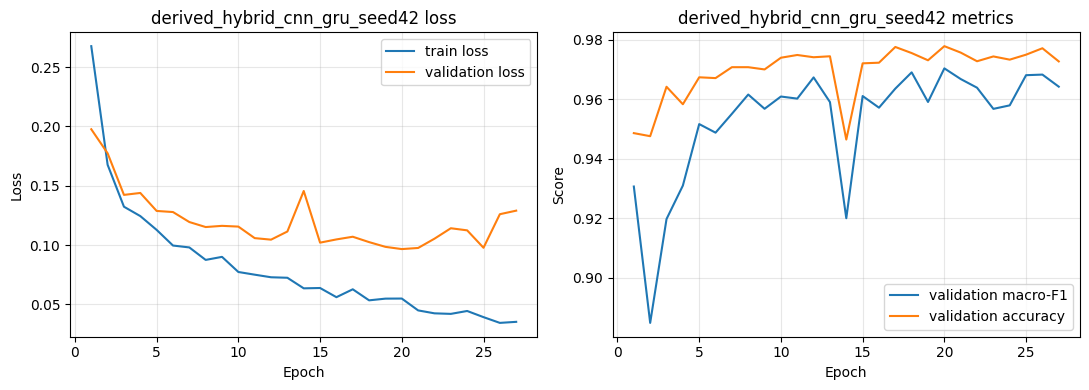

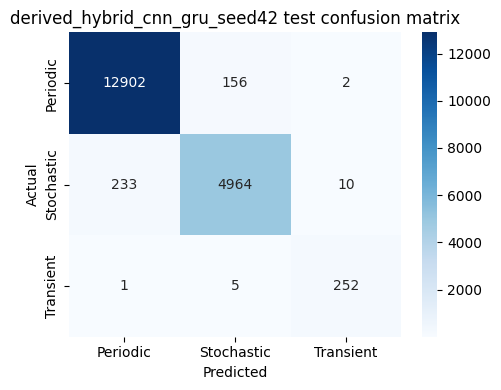

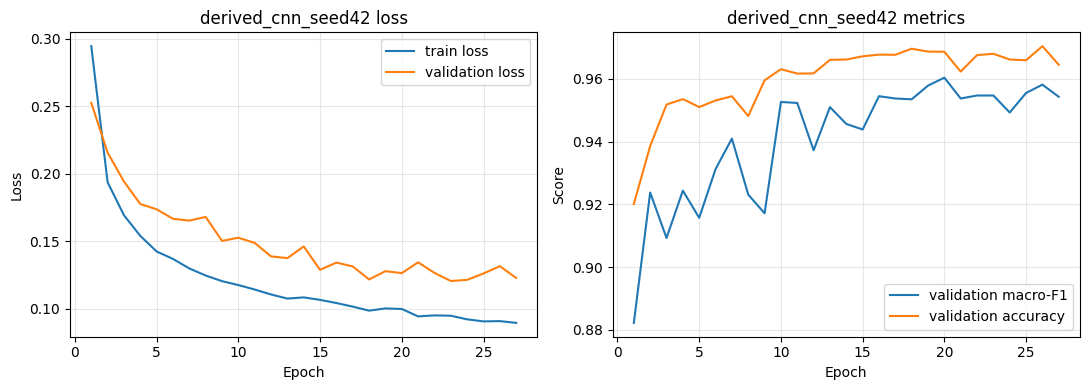

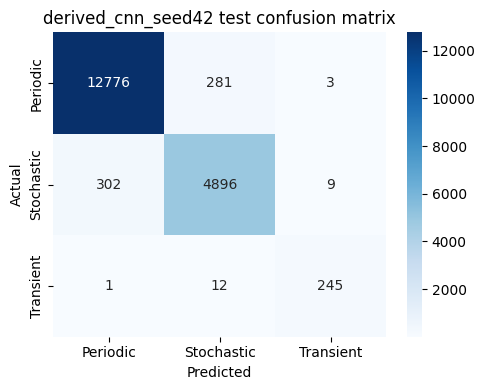

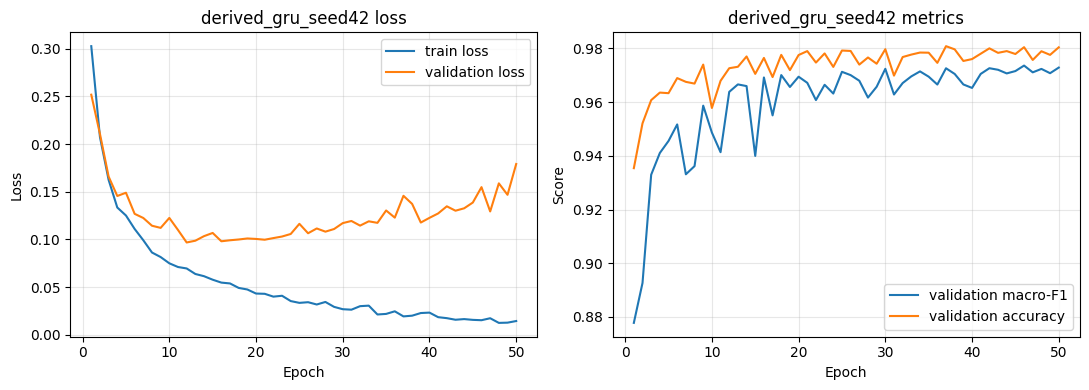

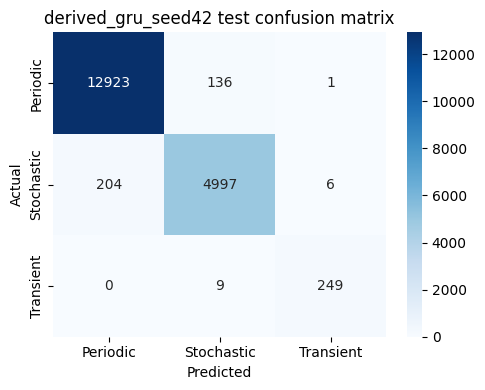

,model,accuracy,balanced_accuracy,macro_f1,best_epoch,stopped_epoch
2,derived_gru_seed42,0.980783,0.971432,0.973849,46,50
0,derived_hybrid_cnn_gru_seed42,0.978030,0.972659,0.970484,20,27
1,derived_cnn_seed42,0.967179,0.956046,0.956967,20,27


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
if RUN_EXPERIMENT:
    summary = []
    for key, result in all_results.items():
        metrics = result['test']
        summary.append({'model': key, 'accuracy': metrics['accuracy'], 'balanced_accuracy': metrics['balanced_accuracy'], 'macro_f1': metrics['macro_f1'], 'best_epoch': result['selection']['best_epoch'], 'stopped_epoch': result['selection']['stopped_epoch']})
        history = result['history']
        epoch_values = [item['epoch'] for item in history]
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        axes[0].plot(epoch_values, [item['train_loss'] for item in history], label='train loss')
        axes[0].plot(epoch_values, [item['loss'] for item in history], label='validation loss')
        axes[0].set(xlabel='Epoch', ylabel='Loss', title=f'{key} loss'); axes[0].legend(); axes[0].grid(alpha=.3)
        axes[1].plot(epoch_values, [item['macro_f1'] for item in history], label='validation macro-F1')
        axes[1].plot(epoch_values, [item['accuracy'] for item in history], label='validation accuracy')
        axes[1].set(xlabel='Epoch', ylabel='Score', title=f'{key} metrics'); axes[1].legend(); axes[1].grid(alpha=.3)
        (ARTIFACT_DIR / 'evaluation' / 'training').mkdir(parents=True, exist_ok=True)
        fig.tight_layout(); fig.savefig(ARTIFACT_DIR / 'evaluation' / 'training' / f'{key}_training_curves.png', dpi=150); plt.show()
        plt.figure(figsize=(5, 4))
        sns.heatmap(metrics['confusion_matrix'], annot=True, fmt='d', cmap='Blues', xticklabels=class_to_index, yticklabels=class_to_index)
        plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(f'{key} test confusion matrix'); plt.tight_layout(); plt.savefig(ARTIFACT_DIR / 'evaluation' / 'training' / f'{key}_confusion_matrix.png', dpi=150); plt.show()
    summary_df = pd.DataFrame(summary).sort_values('macro_f1', ascending=False)
    display(summary_df)
    (ARTIFACT_DIR / 'evaluation' / 'training').mkdir(parents=True, exist_ok=True)
    (ARTIFACT_DIR / 'evaluation' / 'training' / 'derived_experiment_results.json').write_text(json.dumps(all_results, indent=2, default=float), encoding='utf-8')


## Interpretasi eksperimen

Perbandingan dengan enam fitur dasar harus memakai seed 42 dan prosedur training yang sama. Jangan menyimpulkan bahwa fitur derived berhasil hanya dari validation loss; gunakan test macro-F1, balanced accuracy, confusion matrix, dan F1 per kelas. Fitur color belum termasuk dalam notebook ini karena memerlukan pairing g-r berbasis toleransi waktu.